In [4]:
import pandas as pd
import numpy as np

train_path = "D:/Cyber Attack Risk Predictor/data/raw/UNSW_NB15_training-set.csv"
test_path = "D:/Cyber Attack Risk Predictor/data/raw/UNSW_NB15_testing-set.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (175341, 45)
Testing shape: (82332, 45)


In [5]:
# Separate features and target variables

X_train = train_df.drop(columns=["attack_cat", "label", "id"])
X_test = test_df.drop(columns=["attack_cat", "label", "id"])

# Binary classification target
y_train_binary = train_df["label"]
y_test_binary = test_df["label"]

# Multiclass classification target
y_train_multiclass = train_df["attack_cat"]
y_test_multiclass = test_df["attack_cat"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("Binary target shape:", y_train_binary.shape)
print("Multiclass target shape:", y_train_multiclass.shape)

X_train shape: (175341, 42)
X_test shape: (82332, 42)
Binary target shape: (175341,)
Multiclass target shape: (175341,)


In [6]:
from sklearn.preprocessing import OneHotEncoder

# Categorical columns
categorical_features = ["proto", "service", "state"]

# Create encoder
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# Fit on training data and transform both datasets
X_train_encoded = encoder.fit_transform(X_train[categorical_features])
X_test_encoded = encoder.transform(X_test[categorical_features])

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (175341, 155)
Encoded testing shape: (82332, 155)


In [7]:
# Separate numerical features
numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Extract numerical data
X_train_numeric = X_train[numerical_features].to_numpy()
X_test_numeric = X_test[numerical_features].to_numpy()

# Combine numerical + encoded categorical features
X_train_final = np.hstack([X_train_numeric, X_train_encoded])
X_test_final = np.hstack([X_test_numeric, X_test_encoded])

print("Final training feature shape:", X_train_final.shape)
print("Final testing feature shape:", X_test_final.shape)

Final training feature shape: (175341, 194)
Final testing feature shape: (82332, 194)


In [8]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
binary_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

print("Training Binary Random Forest Model...")

# Train the model
binary_model.fit(X_train_final, y_train_binary)

print("Binary model training completed!")

Training Binary Random Forest Model...
Binary model training completed!


In [9]:
# Predict on the testing dataset

y_pred_binary = binary_model.predict(X_test_final)

print("Predictions generated!")
print("Number of predictions:", len(y_pred_binary))

Predictions generated!
Number of predictions: 82332


===== BINARY MODEL RESULTS =====
Accuracy : 0.8936
Precision: 0.8522
Recall   : 0.9760
F1-Score : 0.9099

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Normal       0.96      0.79      0.87     37000
      Attack       0.85      0.98      0.91     45332

    accuracy                           0.89     82332
   macro avg       0.91      0.88      0.89     82332
weighted avg       0.90      0.89      0.89     82332



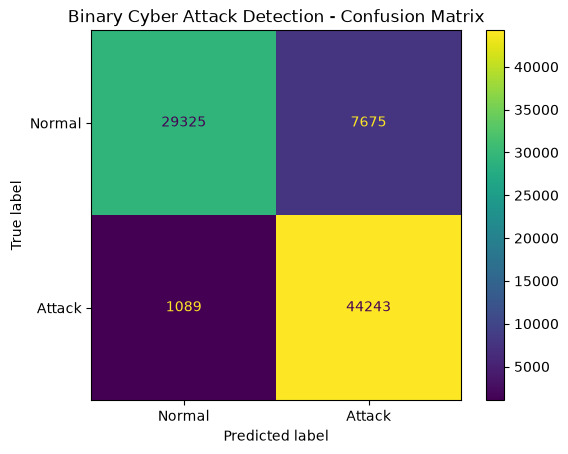

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy = accuracy_score(y_test_binary, y_pred_binary)
precision = precision_score(y_test_binary, y_pred_binary)
recall = recall_score(y_test_binary, y_pred_binary)
f1 = f1_score(y_test_binary, y_pred_binary)

print("===== BINARY MODEL RESULTS =====")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test_binary,
    y_pred_binary,
    target_names=["Normal", "Attack"]
))

# Confusion matrix
cm = confusion_matrix(y_test_binary, y_pred_binary)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

disp.plot()
plt.title("Binary Cyber Attack Detection - Confusion Matrix")
plt.show()

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Create multiclass Random Forest model
multiclass_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

print("Training Multiclass Random Forest Model...")

# Train the model
multiclass_model.fit(
    X_train_final,
    y_train_multiclass
)

print("Multiclass model training completed!")

Training Multiclass Random Forest Model...
Multiclass model training completed!


In [12]:
# Generate attack-category predictions

y_pred_multiclass = multiclass_model.predict(X_test_final)

print("Multiclass predictions generated!")
print("Number of predictions:", len(y_pred_multiclass))

Multiclass predictions generated!
Number of predictions: 82332


In [13]:
from sklearn.metrics import accuracy_score, classification_report

multiclass_accuracy = accuracy_score(
    y_test_multiclass,
    y_pred_multiclass
)

print("===== MULTICLASS MODEL RESULTS =====")
print(f"Accuracy: {multiclass_accuracy:.4f}")

print("\n===== CLASSIFICATION REPORT =====")

print(classification_report(
    y_test_multiclass,
    y_pred_multiclass
))

===== MULTICLASS MODEL RESULTS =====
Accuracy: 0.6923

===== CLASSIFICATION REPORT =====
                precision    recall  f1-score   support

      Analysis       0.01      0.02      0.01       677
      Backdoor       0.05      0.62      0.10       583
           DoS       0.38      0.18      0.24      4089
      Exploits       0.78      0.63      0.70     11132
       Fuzzers       0.26      0.70      0.38      6062
       Generic       1.00      0.96      0.98     18871
        Normal       0.99      0.63      0.77     37000
Reconnaissance       0.86      0.84      0.85      3496
     Shellcode       0.27      0.79      0.41       378
         Worms       0.71      0.50      0.59        44

      accuracy                           0.69     82332
     macro avg       0.53      0.59      0.50     82332
  weighted avg       0.86      0.69      0.74     82332



In [14]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate balanced weights for each attack category
classes = np.unique(y_train_multiclass)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_multiclass
)

class_weight_dict = dict(zip(classes, class_weights))

print("Class weights:")
for cls, weight in class_weight_dict.items():
    print(f"{cls}: {weight:.4f}")

Class weights:
Analysis: 8.7670
Backdoor: 10.0424
DoS: 1.4297
Exploits: 0.5251
Fuzzers: 0.9643
Generic: 0.4384
Normal: 0.3131
Reconnaissance: 1.6713
Shellcode: 15.4758
Worms: 134.8777


In [16]:
# Encode categorical input features

categorical_features = ["proto", "service", "state"]

# Remove target columns and ID
X_train_raw = train_df.drop(columns=["attack_cat", "label", "id"])
X_test_raw = test_df.drop(columns=["attack_cat", "label", "id"])

# Convert categorical columns into numerical columns
X_train = pd.get_dummies(
    X_train_raw,
    columns=categorical_features
)

X_test = pd.get_dummies(
    X_test_raw,
    columns=categorical_features
)

# Make sure training and testing have exactly the same columns
X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)

print("Encoded training shape:", X_train.shape)
print("Encoded testing shape:", X_test.shape)

print("\nAll features are now numerical:")
print(X_train.dtypes.value_counts())

Encoded training shape: (175341, 194)
Encoded testing shape: (82332, 194)

All features are now numerical:
bool       155
int64       28
float64     11
Name: count, dtype: int64


In [17]:
from sklearn.ensemble import RandomForestClassifier

balanced_model = RandomForestClassifier(
    n_estimators=150,
    class_weight=class_weight_dict,
    random_state=42,
    n_jobs=-1
)

print("Training balanced multiclass model...")

balanced_model.fit(X_train, y_train_multiclass)

print("Training completed!")

Training balanced multiclass model...
Training completed!


In [18]:
# Predict attack categories using the balanced model

y_pred_balanced = balanced_model.predict(X_test)

print("Balanced model predictions completed!")
print("Number of predictions:", len(y_pred_balanced))

Balanced model predictions completed!
Number of predictions: 82332


In [19]:
from sklearn.metrics import accuracy_score, classification_report

balanced_accuracy = accuracy_score(y_test_multiclass, y_pred_balanced)

print("===== BALANCED MULTICLASS MODEL RESULTS =====")
print(f"Accuracy: {balanced_accuracy:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test_multiclass,
    y_pred_balanced
))

===== BALANCED MULTICLASS MODEL RESULTS =====
Accuracy: 0.6917

===== CLASSIFICATION REPORT =====
                precision    recall  f1-score   support

      Analysis       0.01      0.03      0.01       677
      Backdoor       0.05      0.60      0.09       583
           DoS       0.40      0.17      0.23      4089
      Exploits       0.78      0.63      0.70     11132
       Fuzzers       0.26      0.71      0.38      6062
       Generic       1.00      0.96      0.98     18871
        Normal       0.99      0.62      0.77     37000
Reconnaissance       0.86      0.84      0.85      3496
     Shellcode       0.27      0.81      0.41       378
         Worms       0.65      0.50      0.56        44

      accuracy                           0.69     82332
     macro avg       0.53      0.59      0.50     82332
  weighted avg       0.86      0.69      0.74     82332



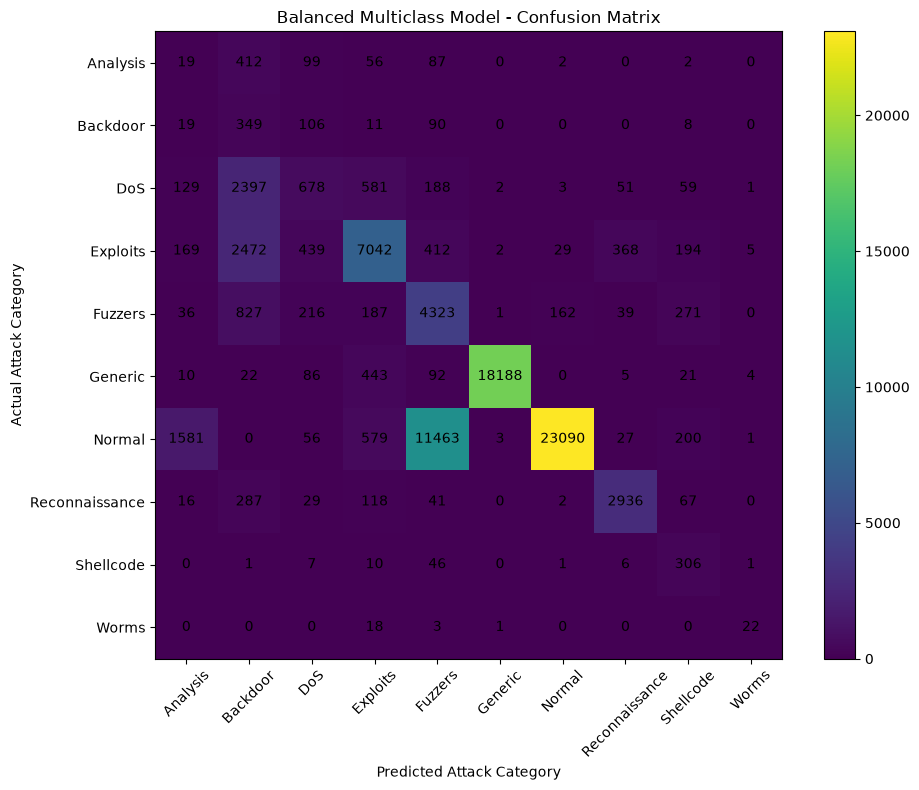

In [21]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm_balanced = confusion_matrix(
    y_test_multiclass,
    y_pred_balanced,
    labels=balanced_model.classes_
)

plt.figure(figsize=(10, 8))

plt.imshow(cm_balanced)

plt.title("Balanced Multiclass Model - Confusion Matrix")
plt.xlabel("Predicted Attack Category")
plt.ylabel("Actual Attack Category")

plt.xticks(
    range(len(balanced_model.classes_)),
    balanced_model.classes_,
    rotation=45
)

plt.yticks(
    range(len(balanced_model.classes_)),
    balanced_model.classes_
)

# Display numbers inside the matrix
for i in range(cm_balanced.shape[0]):
    for j in range(cm_balanced.shape[1]):
        plt.text(
            j,
            i,
            cm_balanced[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [22]:
# Feature importance from the balanced Random Forest

import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": balanced_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Most Important Features:")
print(feature_importance.head(15))

Top 15 Most Important Features:
              Feature  Importance
3              sbytes    0.100678
23              smean    0.084570
32     ct_dst_src_ltm    0.045463
37         ct_srv_dst    0.044668
8               sload    0.040885
27         ct_srv_src    0.037612
6                sttl    0.032939
172         service_-    0.031830
4              dbytes    0.030103
24              dmean    0.027704
9               dload    0.026371
158         proto_udp    0.024833
5                rate    0.024815
0                 dur    0.023495
31   ct_dst_sport_ltm    0.021609


In [23]:
# Select the top 15 most important features

top_15_features = feature_importance.head(15)["Feature"].tolist()

X_train_top15 = X_train[top_15_features]
X_test_top15 = X_test[top_15_features]

print("Top 15 features:")
print(top_15_features)

print("\nTraining shape:", X_train_top15.shape)
print("Testing shape:", X_test_top15.shape)

Top 15 features:
['sbytes', 'smean', 'ct_dst_src_ltm', 'ct_srv_dst', 'sload', 'ct_srv_src', 'sttl', 'service_-', 'dbytes', 'dmean', 'dload', 'proto_udp', 'rate', 'dur', 'ct_dst_sport_ltm']

Training shape: (175341, 15)
Testing shape: (82332, 15)


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

top15_model = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    n_jobs=-1
)

print("Training Top-15 feature model...")

top15_model.fit(
    X_train_top15,
    y_train_multiclass
)

print("Training completed!")

Training Top-15 feature model...
Training completed!


In [25]:
y_pred_top15 = top15_model.predict(X_test_top15)

print("Top-15 model predictions completed!")
print("Number of predictions:", len(y_pred_top15))

Top-15 model predictions completed!
Number of predictions: 82332


In [26]:
top15_accuracy = accuracy_score(
    y_test_multiclass,
    y_pred_top15
)

print("===== TOP-15 FEATURE MODEL RESULTS =====")
print(f"Accuracy: {top15_accuracy:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test_multiclass,
    y_pred_top15
))

===== TOP-15 FEATURE MODEL RESULTS =====
Accuracy: 0.7682

===== CLASSIFICATION REPORT =====
                precision    recall  f1-score   support

      Analysis       0.01      0.02      0.02       677
      Backdoor       0.05      0.09      0.07       583
           DoS       0.60      0.14      0.22      4089
      Exploits       0.59      0.86      0.70     11132
       Fuzzers       0.29      0.56      0.38      6062
       Generic       1.00      0.97      0.99     18871
        Normal       0.96      0.76      0.85     37000
Reconnaissance       0.93      0.79      0.85      3496
     Shellcode       0.33      0.74      0.46       378
         Worms       0.66      0.52      0.58        44

      accuracy                           0.77     82332
     macro avg       0.54      0.54      0.51     82332
  weighted avg       0.83      0.77      0.78     82332



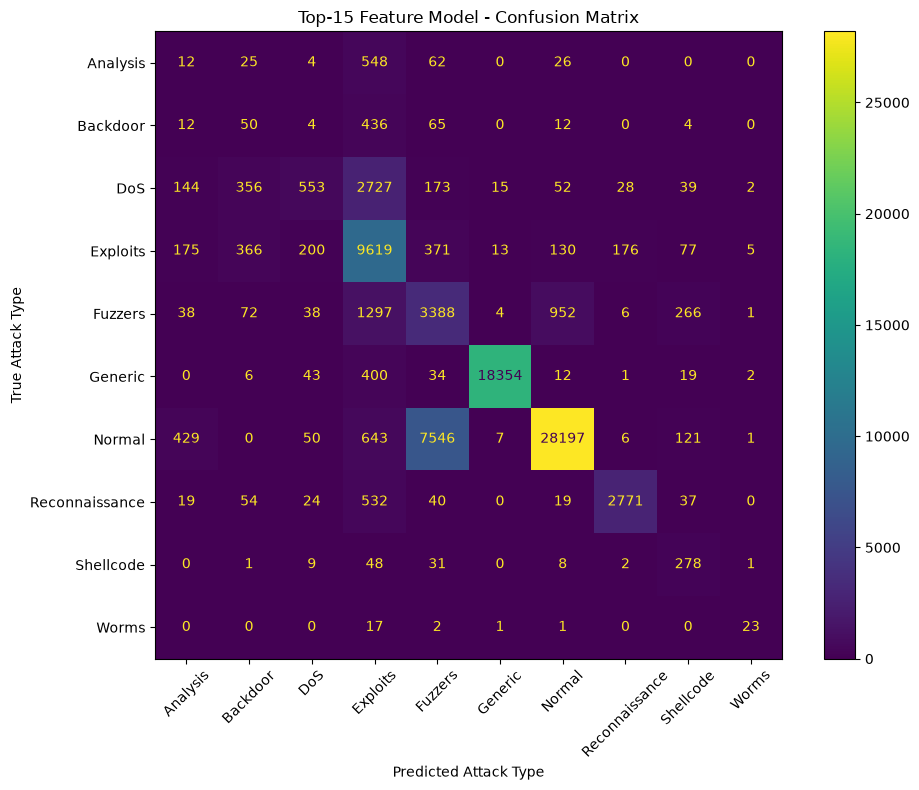

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm_top15 = confusion_matrix(
    y_test_multiclass,
    y_pred_top15,
    labels=top15_model.classes_
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_top15,
    display_labels=top15_model.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, xticks_rotation=45)

plt.title("Top-15 Feature Model - Confusion Matrix")
plt.xlabel("Predicted Attack Type")
plt.ylabel("True Attack Type")
plt.tight_layout()
plt.show()

In [28]:
# Model Performance Comparison

model_comparison = {
    "Binary Model": {
        "Accuracy": 0.8936,
        "Precision": 0.8522,
        "Recall": 0.9760,
        "F1-Score": 0.9099
    },

    "Multiclass Model": {
        "Accuracy": 0.6923,
        "Precision": 0.86,
        "Recall": 0.69,
        "F1-Score": 0.74
    },

    "Balanced Multiclass": {
        "Accuracy": 0.6917,
        "Precision": 0.86,
        "Recall": 0.69,
        "F1-Score": 0.74
    },

    "Top-15 Feature Model": {
        "Accuracy": 0.7682,
        "Precision": 0.83,
        "Recall": 0.77,
        "F1-Score": 0.78
    }
}

comparison_df = pd.DataFrame(model_comparison).T

print("===== MODEL PERFORMANCE COMPARISON =====")
display(comparison_df.round(4))

===== MODEL PERFORMANCE COMPARISON =====


,Accuracy,Precision,Recall,F1-Score
Binary Model,0.8936,0.8522,0.976,0.9099
Multiclass Model,0.6923,0.8600,0.690,0.7400
Balanced Multiclass,0.6917,0.8600,0.690,0.7400
Top-15 Feature Model,0.7682,0.8300,0.770,0.7800


In [30]:
top15_features = [
    'sbytes',
    'smean',
    'ct_dst_src_ltm',
    'ct_srv_dst',
    'sload',
    'ct_srv_src',
    'sttl',
    'service_',
    'dbytes',
    'dmean',
    'dload',
    'proto_udp',
    'rate',
    'dur',
    'ct_dst_sport_ltm'
]

print("Top-15 features used by final model:")
print(top15_features)

print("\nNumber of features:", len(top15_features))

print("\nModel type:")
print(type(top15_model))

Top-15 features used by final model:
['sbytes', 'smean', 'ct_dst_src_ltm', 'ct_srv_dst', 'sload', 'ct_srv_src', 'sttl', 'service_', 'dbytes', 'dmean', 'dload', 'proto_udp', 'rate', 'dur', 'ct_dst_sport_ltm']

Number of features: 15

Model type:
<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [31]:
import os
import joblib

# Path to our project's models folder
model_dir = r"D:\Cyber Attack Risk Predictor\ml\models"

# Make sure the folder exists
os.makedirs(model_dir, exist_ok=True)

# Save the trained Top-15 model
joblib.dump(
    top15_model,
    os.path.join(model_dir, "top15_model.pkl")
)

# Save the list of features used by the model
joblib.dump(
    top15_features,
    os.path.join(model_dir, "top15_features.pkl")
)

print("✅ Model saved successfully!")
print("✅ Feature list saved successfully!")

✅ Model saved successfully!
✅ Feature list saved successfully!


In [32]:
import joblib

model_path = r"D:\Cyber Attack Risk Predictor\ml\models\top15_model.pkl"
features_path = r"D:\Cyber Attack Risk Predictor\ml\models\top15_features.pkl"

# Load saved model
loaded_model = joblib.load(model_path)

# Load saved feature list
loaded_features = joblib.load(features_path)

print("✅ Model loaded successfully!")
print("✅ Feature list loaded successfully!")

print("\nNumber of features:", len(loaded_features))
print("Model type:", type(loaded_model))

✅ Model loaded successfully!
✅ Feature list loaded successfully!

Number of features: 15
Model type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [33]:
def predict_attack(sample):
    """
    Predict the cyber attack category for one network traffic sample.
    """

    # Convert input into DataFrame
    sample_df = pd.DataFrame([sample])

    # Keep only the features used by our final model
    sample_features = sample_df[loaded_features]

    # Make prediction
    prediction = loaded_model.predict(sample_features)[0]

    # Get prediction probabilities
    probabilities = loaded_model.predict_proba(sample_features)[0]

    # Find confidence
    confidence = max(probabilities)

    return {
        "prediction": prediction,
        "confidence": confidence
    }


print("✅ Prediction function created!")

✅ Prediction function created!


In [34]:
print("Checking Top-15 test data...")

print("X_test_top15 shape:", X_test_top15.shape)
print("Expected features:", len(loaded_features))

print("\nFeatures:")
print(X_test_top15.columns.tolist())

Checking Top-15 test data...
X_test_top15 shape: (82332, 15)
Expected features: 15

Features:
['sbytes', 'smean', 'ct_dst_src_ltm', 'ct_srv_dst', 'sload', 'ct_srv_src', 'sttl', 'service_-', 'dbytes', 'dmean', 'dload', 'proto_udp', 'rate', 'dur', 'ct_dst_sport_ltm']


In [36]:
# Take one real sample
sample = X_test_top15.iloc[[0]]

# Make prediction
prediction = loaded_model.predict(sample)[0]

# Get probabilities
probabilities = loaded_model.predict_proba(sample)[0]

# Get confidence
confidence = max(probabilities)

print("===== CYBER ATTACK PREDICTION =====")
print("Predicted class:", prediction)
print("Confidence:", round(confidence * 100, 2), "%")

===== CYBER ATTACK PREDICTION =====
Predicted class: Fuzzers
Confidence: 42.16 %


In [37]:
# Test predictions on 10 real samples

samples = X_test_top15.iloc[:10]

predictions = loaded_model.predict(samples)
probabilities = loaded_model.predict_proba(samples)

results = pd.DataFrame({
    "Actual": y_test_multiclass.iloc[:10].values,
    "Predicted": predictions,
    "Confidence (%)": [
        round(max(prob) * 100, 2)
        for prob in probabilities
    ]
})

print("===== SAMPLE PREDICTIONS =====")
display(results)

===== SAMPLE PREDICTIONS =====


,Actual,Predicted,Confidence (%)
0,Normal,Fuzzers,42.16
1,Normal,Normal,60.22
2,Normal,Fuzzers,67.12
3,Normal,Fuzzers,85.33
4,Normal,Fuzzers,86.67
5,Normal,Fuzzers,75.25
6,Normal,Normal,46.00
7,Normal,Fuzzers,56.00
8,Normal,Normal,100.00
9,Normal,Normal,100.00


In [38]:
# Test one sample from each attack category

test_results = []

for attack_type in y_test_multiclass.unique():

    # Find the first sample belonging to this attack type
    index = y_test_multiclass[y_test_multiclass == attack_type].index[0]

    sample = X_test_top15.loc[[index]]

    # Prediction
    prediction = loaded_model.predict(sample)[0]

    # Probability
    probabilities = loaded_model.predict_proba(sample)[0]
    confidence = max(probabilities)

    test_results.append({
        "Actual": attack_type,
        "Predicted": prediction,
        "Confidence (%)": round(confidence * 100, 2)
    })

demo_results = pd.DataFrame(test_results)

print("===== ATTACK CATEGORY PREDICTION DEMO =====")
display(demo_results)

===== ATTACK CATEGORY PREDICTION DEMO =====


,Actual,Predicted,Confidence (%)
0,Normal,Fuzzers,42.16
1,Reconnaissance,Exploits,36.67
2,Backdoor,Exploits,36.67
3,DoS,Exploits,36.67
4,Exploits,Exploits,50.65
5,Analysis,Exploits,18.10
6,Fuzzers,Exploits,57.15
7,Worms,Exploits,62.53
8,Shellcode,Shellcode,90.00
9,Generic,Generic,100.00


In [39]:
print("===== FINAL MODEL VERIFICATION =====")

print("Model:", type(top15_model).__name__)
print("Number of features:", top15_model.n_features_in_)

print("\nFeatures expected by model:")
print(top15_features)

print("\nTest data shape:", X_test_top15.shape)

print("\nFirst 5 predictions:")
predictions = top15_model.predict(X_test_top15.iloc[:5])

for i, pred in enumerate(predictions):
    print(f"Sample {i+1}: {pred}")

===== FINAL MODEL VERIFICATION =====
Model: RandomForestClassifier
Number of features: 15

Features expected by model:
['sbytes', 'smean', 'ct_dst_src_ltm', 'ct_srv_dst', 'sload', 'ct_srv_src', 'sttl', 'service_', 'dbytes', 'dmean', 'dload', 'proto_udp', 'rate', 'dur', 'ct_dst_sport_ltm']

Test data shape: (82332, 15)

First 5 predictions:
Sample 1: Fuzzers
Sample 2: Normal
Sample 3: Fuzzers
Sample 4: Fuzzers
Sample 5: Fuzzers


In [40]:
import joblib
import os

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the final Top-15 model
model_path = "../models/cyber_attack_multiclass_model.pkl"

joblib.dump(top15_model, model_path)

print("Model saved successfully!")
print("Saved to:", model_path)

Model saved successfully!
Saved to: ../models/cyber_attack_multiclass_model.pkl


In [41]:
import os

print(os.path.exists("../models/cyber_attack_multiclass_model.pkl"))

True


In [42]:
import joblib
import os

# Create models folder
os.makedirs("../models", exist_ok=True)

# Save the exact feature list used by the model
features_path = "../models/top15_features.pkl"

joblib.dump(top15_features, features_path)

print("Feature list saved successfully!")
print("Saved to:", features_path)
print("\nFeatures:")
print(top15_features)

Feature list saved successfully!
Saved to: ../models/top15_features.pkl

Features:
['sbytes', 'smean', 'ct_dst_src_ltm', 'ct_srv_dst', 'sload', 'ct_srv_src', 'sttl', 'service_', 'dbytes', 'dmean', 'dload', 'proto_udp', 'rate', 'dur', 'ct_dst_sport_ltm']


In [43]:
classes_path = "../models/attack_classes.pkl"

joblib.dump(top15_model.classes_, classes_path)

print("Attack classes saved successfully!")
print("Saved to:", classes_path)

Attack classes saved successfully!
Saved to: ../models/attack_classes.pkl
